In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [2]:
df_90 = pd.read_csv('summary-90.csv')
df_99 = pd.read_csv('summary-99.csv')
df_90.head()

,url,crate_name,members_count,dependencies_count,crates_io_downloads,github_stars,analysis_total_time_seconds,analysis_peak_rss_MB,total_fns,total_traits,...,macro_fn_already_specialized_fns,macro_fn_already_specialized_traits,macro_fn_newly_specializable_fn_pairs,macro_fn_newly_specializable_trait_pairs,macro_fn_newly_specializable_fns,macro_fn_newly_specializable_traits,macro_fn_already_specializable_unspecialized_fn_pairs,macro_fn_already_specializable_unspecialized_trait_pairs,macro_fn_already_specializable_unspecialized_fns,macro_fn_already_specializable_unspecialized_traits
0,https://github.com/dtolnay/syn,syn,10,10,1169638606,3215,167.117,200,11140,129,...,0,0,41484,15,1188,12,162,15,78,9
1,https://github.com/rust-lang/hashbrown,hashbrown,1,13,948648240,2799,0.767,106,727,34,...,0,0,0,0,0,0,0,0,0,0
2,https://github.com/bitflags/bitflags,bitflags,1,11,871628003,1068,0.058,90,161,26,...,0,0,18,9,20,8,9,8,18,8
3,https://github.com/dtolnay/proc-macro2,proc-macro2,2,6,806768972,880,3.200,96,460,16,...,0,0,0,0,0,0,0,0,0,0
4,https://github.com/dtolnay/quote,quote,1,3,788009739,1485,3.563,89,395,32,...,0,0,0,0,0,0,0,0,0,0


In [6]:
total_fns = df_90['total_fns']
total_traits = df_90['total_traits']
spec_fns_90 = df_90['all_fn_specializable_fns'] / total_fns
spec_fns_99 = df_99['all_fn_specializable_fns'] / total_fns

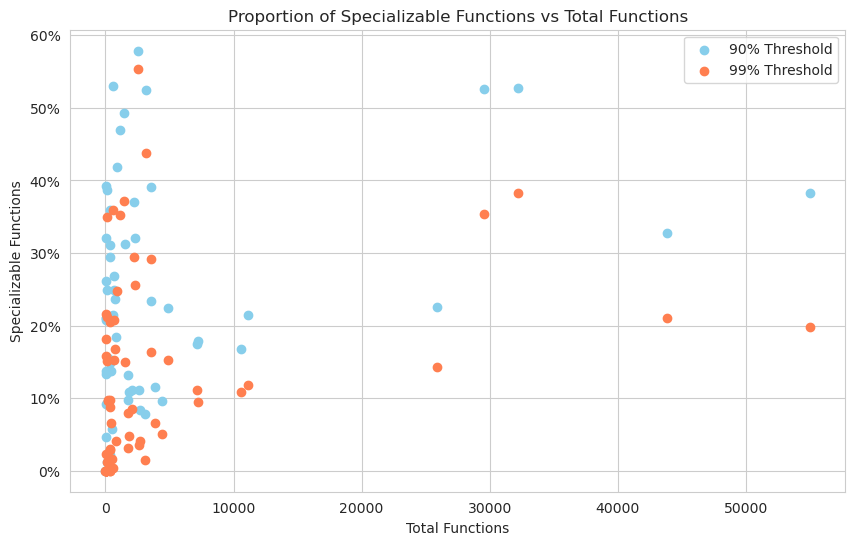

In [110]:
plt.figure(figsize=(10, 6))
plt.scatter(total_fns, spec_fns_90, color='skyblue')
plt.scatter(total_fns, spec_fns_99, color='coral')
plt.title('Proportion of Specializable Functions vs Total Functions')
plt.xlabel('Total Functions')
plt.ylabel('Specializable Functions')
plt.grid(True)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.legend(['90% Threshold', '99% Threshold'])
plt.show()

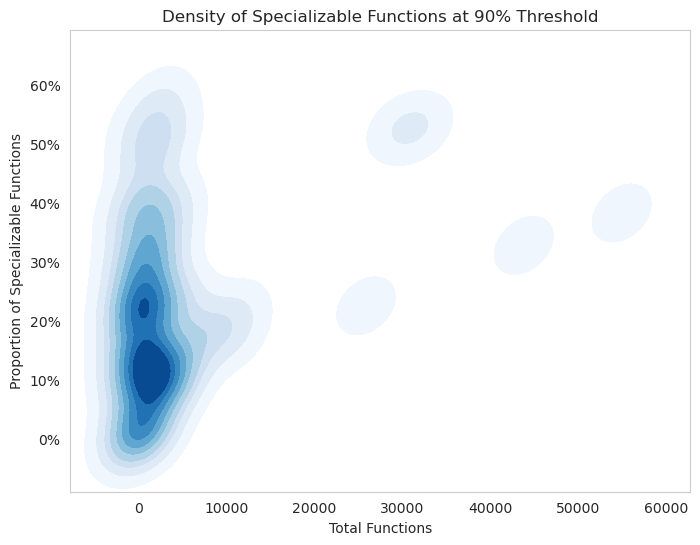

In [17]:
plt.figure(figsize=(8, 6))
sns.kdeplot(x=total_fns, y=spec_fns_90, cmap="Blues", fill=True, bw_adjust=.5)
plt.title('Density of Specializable Functions at 90% Threshold')
plt.xlabel('Total Functions')
plt.ylabel('Proportion of Specializable Functions')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.grid(False)
plt.ylim(bottom=-0.09)
plt.show()

/tmp/ipykernel_10446/2290578906.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


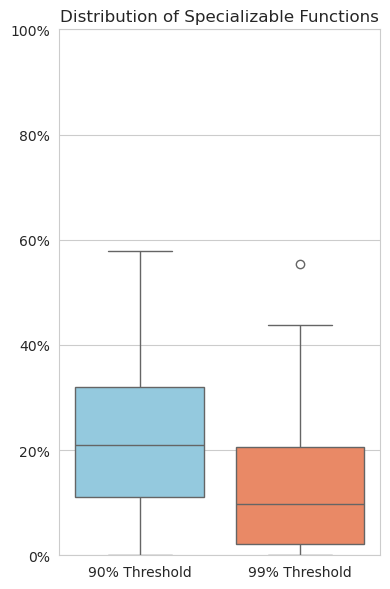

In [28]:
sns.set_style("whitegrid")

plt.figure(figsize=(4, 6))
sns.boxplot(
    x=['90% Threshold'] * len(spec_fns_90) + ['99% Threshold'] * len(spec_fns_99),
    y=list(spec_fns_90) + list(spec_fns_99),
    palette={'90% Threshold': 'skyblue', '99% Threshold': 'coral'}
)

plt.title('Distribution of Specializable Functions')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [10]:
bare_fns_90 = df_90['bare_fn_specializable_fns'] / df_90['total_bare_fns']
bare_fns_99 = df_99['bare_fn_specializable_fns'] / df_99['total_bare_fns']
trait_fns_90 = df_90['trait_fn_specializable_fns'] / df_90['total_trait_fns']
trait_fns_99 = df_99['trait_fn_specializable_fns'] / df_99['total_trait_fns']
trait_impl_fns_90 = df_90['trait_impl_fn_specializable_fns'] / df_90['total_trait_impl_fns']
trait_impl_fns_99 = df_99['trait_impl_fn_specializable_fns'] / df_99['total_trait_impl_fns']
inherent_impl_fns_90 = df_90['inherent_impl_fn_specializable_fns'] / df_90['total_inherent_impl_fns']
inherent_impl_fns_99 = df_99['inherent_impl_fn_specializable_fns'] / df_99['total_inherent_impl_fns']

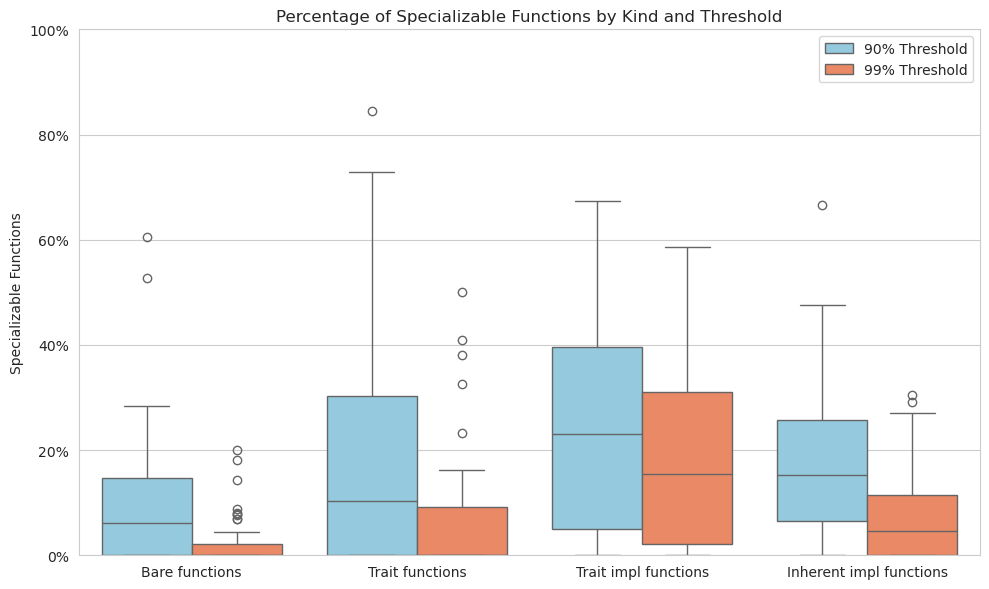

In [86]:
sns.set_style("whitegrid")

labels = []
thresholds = []
values = []

for label, vals_90, vals_99 in [
    ('Bare functions', bare_fns_90, bare_fns_99),
    ('Trait functions', trait_fns_90, trait_fns_99),
    ('Trait impl functions', trait_impl_fns_90, trait_impl_fns_99),
    ('Inherent impl functions', inherent_impl_fns_90, inherent_impl_fns_99),
]:
    labels += [label] * (len(vals_90) + len(vals_99))
    thresholds += ['90% Threshold'] * len(vals_90) + ['99% Threshold'] * len(vals_99)
    values += list(vals_90) + list(vals_99)

plt.figure(figsize=(10, 6))
sns.boxplot(
    x=labels,
    y=values,
    hue=thresholds,
    palette={
        '90% Threshold': 'skyblue',
        '99% Threshold': 'coral',
    },
)

plt.title('Percentage of Specializable Functions by Kind and Threshold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.ylabel('Specializable Functions')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

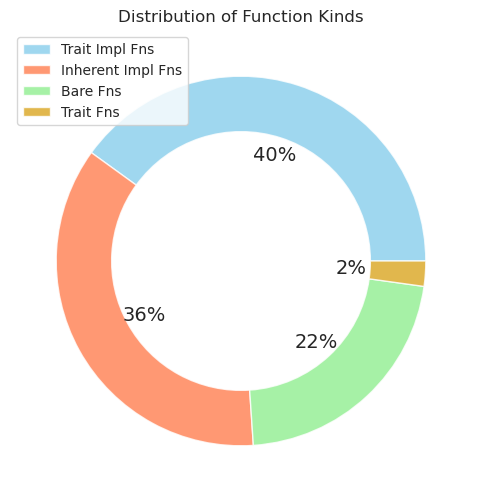

In [ ]:
perc = [
    (df_90['total_trait_impl_fns'] / df_90['total_fns']).mean(),
    (df_90['total_inherent_impl_fns'] / df_90['total_fns']).mean(),
    (df_90['total_bare_fns'] / df_90['total_fns']).mean(),
    (df_90['total_trait_fns'] / df_90['total_fns']).mean(), 
]

plt.figure(figsize=(6, 6))
plt.pie(
    perc, 
    autopct='%1.0f%%',
    textprops={'fontsize': 14},
    wedgeprops=dict(width=0.3, alpha=0.8),
    colors=['skyblue', 'coral', 'lightgreen', 'goldenrod']
)
plt.title('Distribution of Function Kinds')
plt.legend(['Trait Impl Fns', 'Inherent Impl Fns', 'Bare Fns', 'Trait Fns'], loc='upper left')
plt.show()

In [14]:
avg_already_spec_90 = (df_90['all_fn_already_specializable_fns'] / total_fns).mean()
avg_newly_spec_90 = (df_90['all_fn_newly_specializable_fns'] / total_fns).mean()
avg_already_spec_99 = (df_99['all_fn_already_specializable_fns'] / total_fns).mean()
avg_newly_spec_99 = (df_99['all_fn_newly_specializable_fns'] / total_fns).mean()

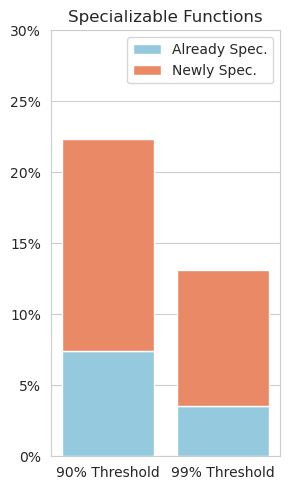

In [121]:
x_position = [0, 1]
plt.figure(figsize=(3, 5)) 

sns.barplot(
    x=x_position,
    y=[avg_already_spec_90, avg_already_spec_99],
    label='Already Spec.',
    color='skyblue'
)
sns.barplot(
    x=x_position,
    y=[avg_newly_spec_90, avg_newly_spec_99],
    label='Newly Spec.',
    color='coral',
    bottom=[avg_already_spec_90, avg_already_spec_99] 
)

plt.title('Specializable Functions')
plt.ylim(0, 0.3) 
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
plt.xticks(x_position, ['90% Threshold', '99% Threshold'])
plt.legend()

plt.tight_layout()
plt.show()